# Energy budget of the CESM2(WACCM6) 1850 piControl, years 1–100

Over the first 100 years, the ocean heat content (OHC) of `b.e21.BW1850.f09_g17.CMIP6-piControl.001` rises by
about twice the energy that the integrated top-of-atmosphere imbalance (iEEI) says entered the climate system.
This notebook follows that energy through every heat flux into and out of the ocean, and through the sea-ice, land
and atmosphere reservoirs the ocean exchanges energy with, to separate the parts of the budget that **close**
(verified) from the parts that **don't** (called into question). Section 4 puts the mismatch in scale, and
Section 5 explains why global surface temperature stays flat while the system gains energy.

**Inputs** (all written by the pipelines in this directory):

| File | Pipeline | Contents |
|---|---|---|
| `*.iEEI.y1-100.nc` | `run_ieei_piControl.py` | global-mean EEI = FSNT − FLNT and its time integral |
| `*.OHC.y1-100.nc` | `run_ohc_piControl.py` | OHC by depth bin, heat gained since year 1, ocean volume |
| `*.fluxes.y1-100.nc` | `run_fluxes_piControl.py` | global-total POP2, CICE, CLM and CAM heat-budget terms |

**Conventions.** Every rate is in **W per m² of Earth's surface** (4πR², CAM radius), positive = energy gained by
the receiving reservoir, so terms from different model grids add and compare directly. A 100-year *flux* is the
month-length-weighted mean; a 100-year *storage* rate is the linear trend of the reservoir's annual means.

In [13]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

ROOT = "/glade/work/wkamp/GEO/PRISM/PRISM/ohc_ieei_rebuild/"
CASE = "b.e21.BW1850.f09_g17.CMIP6-piControl.001"
ieei = xr.open_dataset(f"{ROOT}{CASE}.iEEI.y1-100.nc")
ohc = xr.open_dataset(f"{ROOT}{CASE}.OHC.y1-100.nc")
flx = xr.open_dataset(f"{ROOT}{CASE}.fluxes.y1-100.nc")

# A closure is "verified" when its two sides agree to within TOL [W per m^2 of Earth].
# 0.01 W/m^2 sustained for a century is 1.6e22 J -- about a fifth of the OHC/iEEI mismatch below.
TOL = 0.01

EARTH = flx.attrs["earth_area_m2"]
OCEAN = ohc.attrs["ocean_area_m2"]
RHO_CP = ohc.attrs["rho_kg_m3"] * ohc.attrs["cp_j_kg_k"]  # J m-3 K-1, POP2's own constants
SEC_PER_YEAR = 365 * 86400  # noleap calendar
CENTURY_S = 100 * SEC_PER_YEAR
ZJ = 1e21


def flux_mean(power_W):
    """Month-length-weighted record mean of a global-total flux [W] -> W per m^2 of Earth."""
    days = power_W["time"].dt.days_in_month
    return float((power_W * days).sum() / days.sum()) / EARTH


def storage_rate(state_J):
    """Linear trend of a reservoir's annual-mean state [J] -> W per m^2 of Earth."""
    yearly = annual(state_J)
    return np.polyfit(yearly["year"].values, yearly.values, 1)[0] / SEC_PER_YEAR / EARTH


def cumulative_J(power_W):
    """Running time integral of a global-total flux [W] -> J since the start of the record."""
    return (power_W * power_W["time"].dt.days_in_month * 86400.0).cumsum("time")


def annual(da):
    return da.groupby("time.year").mean()


# Chart styling: reference palette from the dataviz method. Entities keep one color throughout:
# blue = TOA imbalance / iEEI, orange = ocean heat content, aqua = ocean surface heat input.
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GOOD, WARNING, CRITICAL = "#0ca30c", "#fab219", "#d03b3b"  # status only: verified / inconclusive / questioned
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False, "legend.labelcolor": INK2,
    "figure.dpi": 110,
})


def label_bars(ax, bars, values, fmt):
    """Value labels just past each bar end, in text ink (never the series color)."""
    span = np.diff(ax.get_xlim())[0]
    for bar, v in zip(bars, values):
        x = bar.get_x() + bar.get_width()
        ax.text(x + np.sign(v or 1) * 0.01 * span, bar.get_y() + bar.get_height() / 2, fmt(v),
                va="center", ha="left" if v >= 0 else "right", color=INK2, fontsize=9)

## 1. Headline: ocean heat gain vs. integrated TOA imbalance

The first comparison in `file_explorer.ipynb` plotted `OHC_global_mean` (J per m² of **ocean**) against
`iEEI_global_mean` (J per m² of **Earth**). Ocean covers only ~71% of Earth, so that inflates the ratio by ~1.4×.
The OHC record also has a seasonal cycle about a third the size of its 100-year change, so the endpoints chosen
(a single January vs. a single December) shift the ratio further. The table corrects one issue per row.

In [14]:
d_ohc = ohc["dOHC_total_joules"]
d_ohc_full = d_ohc.sel(ohc_depth=-1)
gm = ohc["OHC_global_mean"].sel(ohc_depth=-1)
ieei_J = ieei["iEEI_total_joules"]

headline = pd.DataFrame(
    {
        "OHC gain": [float(gm[-1] - gm[0]), float(d_ohc_full[-1]), float(annual(d_ohc_full)[-1] - annual(d_ohc_full)[0])],
        "iEEI gain": [float(ieei["iEEI_global_mean"][-1]), float(ieei_J[-1]), float(annual(ieei_J)[-1] - annual(ieei_J)[0])],
        "units": ["J/m² of ocean vs. J/m² of Earth", "J", "J"],
    },
    index=[
        "As first plotted: per-m² of different areas, Jan yr 1 → Dec yr 100",
        "Same endpoints, both in total joules",
        "Total joules, annual mean yr 1 → annual mean yr 100",
    ],
)
headline["OHC / iEEI"] = headline["OHC gain"] / headline["iEEI gain"]
display(headline.style.format({"OHC gain": "{:.3e}", "iEEI gain": "{:.3e}", "OHC / iEEI": "{:.2f}"}))

days = ieei["time"].dt.days_in_month
print(f"Mean EEI, plain average of monthly values:   {float(ieei['EEI_global_mean'].mean()):.4f} W/m^2")
print(f"Mean EEI, weighted by month length (correct): {float((ieei['EEI_global_mean'] * days).sum() / days.sum()):.4f} W/m^2")
print("(EEI peaks near perihelion in Jan/Feb, so the plain average over-weights short February.)")

,OHC gain,iEEI gain,units,OHC / iEEI
"As first plotted: per-m² of different areas, Jan yr 1 → Dec yr 100",4.679e+08,1.801e+08,J/m² of ocean vs. J/m² of Earth,2.60
"Same endpoints, both in total joules",1.687e+23,9.185e+22,J,1.84
"Total joules, annual mean yr 1 → annual mean yr 100",1.713e+23,8.251e+22,J,2.08


Mean EEI, plain average of monthly values:   0.1015 W/m^2
Mean EEI, weighted by month length (correct): 0.0571 W/m^2
(EEI peaks near perihelion in Jan/Feb, so the plain average over-weights short February.)


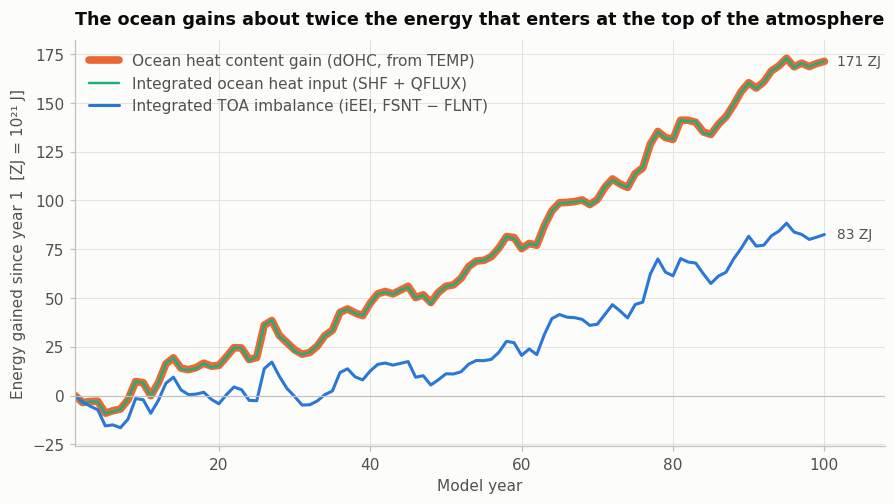

In [15]:
ocn_in_W = flx["SHF"] + flx["QFLUX"] + flx["TFW_T"] + flx["RESID_T"]
# (label, series, color, line width, end label?) -- dOHC is drawn wide underneath because the ocean-input
# line lies almost exactly on top of it.
series = [
    ("Ocean heat content gain (dOHC, from TEMP)", annual(d_ohc_full), ORANGE, 5, True),
    ("Integrated ocean heat input (SHF + QFLUX)", annual(cumulative_J(ocn_in_W)), AQUA, 1.6, False),
    ("Integrated TOA imbalance (iEEI, FSNT − FLNT)", annual(ieei_J), BLUE, 2, True),
]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for label, s, color, lw, end_label in series:
    s = (s - s.isel(year=0)) / ZJ
    ax.plot(s["year"], s, color=color, lw=lw, label=label, solid_capstyle="round")
    if end_label:
        ax.annotate(f"{float(s[-1]):.0f} ZJ", xy=(float(s["year"][-1]), float(s[-1])), xytext=(8, 0),
                    textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xlim(1, 108)
ax.set(xlabel="Model year", ylabel="Energy gained since year 1  [ZJ = 10²¹ J]",
       title="The ocean gains about twice the energy that enters at the top of the atmosphere")
ax.legend(loc="upper left")
plt.show()

The orange (heat content computed from `TEMP`) and aqua (heat POP's own surface fluxes deliver) curves track each
other — the ocean model's books balance. The gap is between them and the blue TOA curve: the ocean receives more
heat than the atmosphere takes in at the top. The rest of the notebook locates where that extra heat appears.

## 2. Every heat flux into and out of the ocean

POP2's coupler heat flux `SHF` is the sum of eight components (POP2 `forcing_coupled`:
SHF = QSW + LWDN + LWUP + SENH + L<sub>v</sub>·EVAP + MELTH − L<sub>f</sub>·(SNOW + IOFF)). On top of `SHF`, POP
applies three internal heat terms: `QFLUX` (latent heat released by frazil-ice formation; negative values are
"melt potential" handed to the sea-ice model), `TFW_T` (heat carried by freshwater fluxes) and `RESID_T`
(free-surface residual). Values below are 100-year means.

In [16]:
coupler = {
    "Shortwave (SHF_QSW)": "SHF_QSW", "Longwave down (LWDN_F)": "LWDN_F", "Longwave up (LWUP_F)": "LWUP_F",
    "Latent (Lv·EVAP_F)": "LATENT", "Sensible (SENH_F)": "SENH_F", "Sea-ice melt (MELTH_F)": "MELTH_F",
    "Snow melt (−Lf·SNOW_F)": "SNOW_MELT", "Ice runoff melt (−Lf·IOFF_F)": "IOFF_MELT",
}
internal = {"Frazil heat (QFLUX)": "QFLUX", "Freshwater heat (TFW_T)": "TFW_T", "Free-surface residual (RESID_T)": "RESID_T"}

rows = [(name, "coupler component", flux_mean(flx[v])) for name, v in coupler.items()]
rows.append(("SHF, net coupler flux", "net", flux_mean(flx["SHF"])))
rows.append(("SHF minus sum of components", "check", flux_mean(flx["SHF_RESIDUAL"])))
rows += [(name, "internal", flux_mean(flx[v])) for name, v in internal.items()]
rows.append(("  QFLUX, positive part (approx.)", "internal (split)", flux_mean(flx["QFLUX_POS"])))
rows.append(("  QFLUX, negative part (approx.)", "internal (split)", flux_mean(flx["QFLUX_NEG"])))
rows.append(("Total heat input (SHF + QFLUX + TFW_T + RESID_T)", "net", flux_mean(ocn_in_W)))
rows.append(("Ocean storage dOHC/dt (from TEMP)", "storage", storage_rate(d_ohc_full)))
ocean_table = pd.DataFrame(rows, columns=["term", "kind", "W/m² of Earth"]).set_index("term")
ocean_table["W/m² of ocean"] = ocean_table["W/m² of Earth"] * EARTH / OCEAN
display(ocean_table.style.format({"W/m² of Earth": "{:+.4f}", "W/m² of ocean": "{:+.4f}"}))

,kind,W/m² of Earth,W/m² of ocean
term,,,
Shortwave (SHF_QSW),coupler component,+121.2679,+171.5859
Longwave down (LWDN_F),coupler component,+242.9275,+343.7260
Longwave up (LWUP_F),coupler component,-277.2691,-392.3171
Latent (Lv·EVAP_F),coupler component,-73.4882,-103.9808
Sensible (SENH_F),coupler component,-12.0446,-17.0423
Sea-ice melt (MELTH_F),coupler component,-0.8339,-1.1799
Snow melt (−Lf·SNOW_F),coupler component,-0.4332,-0.6129
Ice runoff melt (−Lf·IOFF_F),coupler component,-0.0630,-0.0892
"SHF, net coupler flux",net,+0.0634,+0.0897


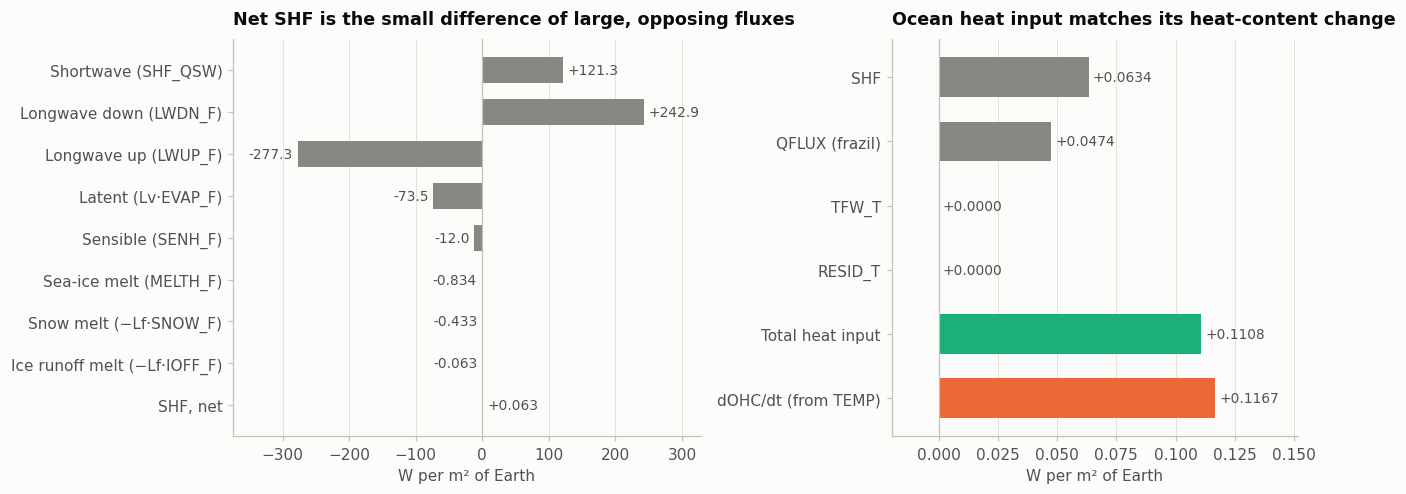

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})

names = list(coupler) + ["SHF, net"]
vals = [flux_mean(flx[v]) for v in coupler.values()] + [flux_mean(flx["SHF"])]
colors = [MUTED] * len(coupler) + [INK2]
bars = ax1.barh(names, vals, color=colors, height=0.62)
ax1.invert_yaxis()
ax1.axvline(0, color=AXIS, lw=0.8)
ax1.set_xlim(min(vals) * 1.35, max(vals) * 1.35)
label_bars(ax1, bars, vals, lambda v: f"{v:+.1f}" if abs(v) >= 1 else f"{v:+.3f}")
ax1.set(xlabel="W per m² of Earth", title="Net SHF is the small difference of large, opposing fluxes")
ax1.grid(axis="y", visible=False)

names2 = ["SHF", "QFLUX (frazil)", "TFW_T", "RESID_T", "Total heat input", "dOHC/dt (from TEMP)"]
vals2 = [flux_mean(flx["SHF"]), flux_mean(flx["QFLUX"]), flux_mean(flx["TFW_T"]), flux_mean(flx["RESID_T"]),
         flux_mean(ocn_in_W), storage_rate(d_ohc_full)]
bars2 = ax2.barh(names2, vals2, color=[MUTED, MUTED, MUTED, MUTED, AQUA, ORANGE], height=0.62)
ax2.invert_yaxis()
ax2.axvline(0, color=AXIS, lw=0.8)
ax2.set_xlim(min(0, min(vals2)) - 0.02, max(vals2) * 1.3)
label_bars(ax2, bars2, vals2, lambda v: f"{v:+.4f}")
ax2.set(xlabel="W per m² of Earth", title="Ocean heat input matches its heat-content change")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 3. Closure checks: verified vs. called into question

Each check compares two independently computed sides of one energy balance. The difference is shown as
side A − side B in W per m² of Earth:

- **✓ verified** — the sides agree to within ±`TOL`;
- **✗ questioned** — an exact comparison that disagrees by more than `TOL`;
- **? inconclusive** — an *approximate* comparison that disagrees by more than `TOL`, where the approximation
  itself could explain the gap, so it cannot settle anything either way.

Storage terms, each the trend of a reservoir *state*:
- **ocean**: dOHC/dt from `TEMP`.
- **sea ice**: CICE ice + snow heat content (`sihc` + `sisnhc`). This is relative to 0 °C seawater, so freezing
  lowers it.
- **land**: snow-pack latent heat (−L<sub>f</sub> × `H2OSNO`) plus soil and bedrock heat content to 42 m (`TSOI`).
  The soil part uses a fixed heat capacity, so it is approximate.
- **atmosphere**: TS trend × the heat capacity of an air column. This is approximate, since it assumes the column
  warms like the surface.

In [18]:
r = {
    "toa_model": flux_mean(flx["TOA_NET_MODEL"]),
    "toa_toa": flux_mean(flx["TOA_NET_TOA"]),
    "sfc": flux_mean(flx["SFC_NET"]),
    "ocn_in": flux_mean(ocn_in_W),
    "ocn": storage_rate(d_ohc_full),
    "ice": storage_rate(flx["ICE_HEAT_CONTENT"] + flx["SNOW_ON_ICE_HEAT_CONTENT"]),
    "land": storage_rate(flx["LAND_SNOW_LATENT_CONTENT"] + flx["LAND_SOIL_HEAT_CONTENT"]),
    "atm": storage_rate(flx["TS_GLOBAL_MEAN"] * (1004.0 * 1.0e5 / 9.81) * EARTH),
}
stored = r["ocn"] + r["ice"] + r["land"] + r["atm"]

land_errors = flx["ERRSEB"] + flx["ERRSOI"] + flx["ERRSOL"]
checks = [  # (check, side A, A, side B, B, notes, approximate?)
    ("iEEI pipeline vs. flux pipeline TOA integral", "iEEI_total_joules / 100 yr", float(ieei_J[-1]) / CENTURY_S / EARTH,
     "flux-pipeline FSNT − FLNT", r["toa_model"], "two independent pipelines", False),
    ("SHF = sum of its 8 components", "SHF", flux_mean(flx["SHF"]), "sum of components",
     flux_mean(flx["SHF"] - flx["SHF_RESIDUAL"]), "POP2 decomposition, CESM latent heats", False),
    ("Sea-ice melt heat: ocean side vs. ice side", "POP MELTH_F", flux_mean(flx["MELTH_F"]),
     "CICE fhocn_ai", flux_mean(flx["FHOCN_AI"]), "coupler hand-off", False),
    ("Frazil heat: ocean side vs. ice side", "POP QFLUX (positive part)", flux_mean(flx["QFLUX_POS"]),
     "CICE frazil growth × ρ_ice·L_f", flux_mean(flx["FRAZIL_LATENT"]),
     "approx.: CICE frazil enthalpy ≠ ρ_ice·L_f; diagnostic definitions may differ", True),
    ("Land model energy conservation", "CLM ERRSEB + ERRSOI + ERRSOL", flux_mean(land_errors), "zero", 0.0,
     "CLM's own error diagnostics", False),
    ("Ocean closure", "dOHC/dt (from TEMP)", r["ocn"], "SHF + QFLUX + TFW_T + RESID_T", r["ocn_in"], "ocean model internal", False),
    ("Atmosphere closure, top of model", "TOA: FSNT − FLNT", r["toa_model"], "surface net + atm. storage",
     r["sfc"] + r["atm"], "iEEI's TOA definition", False),
    ("Atmosphere closure, top of atmosphere", "TOA: FSNTOA − FLUT", r["toa_toa"], "surface net + atm. storage",
     r["sfc"] + r["atm"], "alternate TOA definition", False),
    ("Surface interface", "CAM surface net", r["sfc"], "ocean + sea-ice + land storage",
     r["ocn"] + r["ice"] + r["land"], "atmosphere → surface hand-off", False),
    ("Whole system", "TOA: FSNT − FLNT (iEEI)", r["toa_model"], "ocean + sea-ice + land + atm. storage",
     stored, "the OHC vs. iEEI question", False),
]
check_table = pd.DataFrame(
    checks, columns=["check", "side A", "A [W/m²]", "side B", "B [W/m²]", "notes", "approx"]
).set_index("check")
check_table["A − B [W/m²]"] = check_table["A [W/m²]"] - check_table["B [W/m²]"]
within = check_table["A − B [W/m²]"].abs() <= TOL
check_table["status"] = np.select(
    [within, check_table["approx"]], ["✓ verified", "? inconclusive"], default="✗ questioned"
)
check_table = check_table.drop(columns="approx")
STATUS_COLOR = {"✓": GOOD, "?": WARNING, "✗": CRITICAL}


def status_style(v):
    return f"color: {STATUS_COLOR[v[0]] if v[0] != '?' else INK2}; font-weight: bold"


display(
    check_table.style.format({"A [W/m²]": "{:+.4f}", "B [W/m²]": "{:+.4f}", "A − B [W/m²]": "{:+.4f}"})
    .applymap(status_style, subset=["status"])
)
print("Storage terms [W/m^2 of Earth]: " + ", ".join(f"{k} = {v:+.4f}" for k, v in r.items() if k in ("ocn", "ice", "land", "atm")))
print(f"  land storage split: snow pack {storage_rate(flx['LAND_SNOW_LATENT_CONTENT']):+.4f}, "
      f"soil {storage_rate(flx['LAND_SOIL_HEAT_CONTENT']):+.4f}")
print(f"Why CLM FGR is not used as land storage: mean FGR = {flux_mean(flx['FGR']):+.4f}, of which snow-melt heat "
      f"FSM = {flux_mean(flx['FSM']):+.4f} -- the melt water leaves as runoff, so this heat is cycled, not stored.")

,side A,A [W/m²],side B,B [W/m²],notes,A − B [W/m²],status
check,,,,,,,
iEEI pipeline vs. flux pipeline TOA integral,iEEI_total_joules / 100 yr,+0.0571,flux-pipeline FSNT − FLNT,+0.0571,two independent pipelines,+0.0000,✓ verified
SHF = sum of its 8 components,SHF,+0.0634,sum of components,+0.0634,"POP2 decomposition, CESM latent heats",-0.0000,✓ verified
Sea-ice melt heat: ocean side vs. ice side,POP MELTH_F,-0.8339,CICE fhocn_ai,-0.8339,coupler hand-off,+0.0000,✓ verified
Frazil heat: ocean side vs. ice side,POP QFLUX (positive part),+0.0474,CICE frazil growth × ρ_ice·L_f,+0.1719,approx.: CICE frazil enthalpy ≠ ρ_ice·L_f; diagnostic definitions may differ,-0.1244,? inconclusive
Land model energy conservation,CLM ERRSEB + ERRSOI + ERRSOL,+0.0000,zero,+0.0000,CLM's own error diagnostics,+0.0000,✓ verified
Ocean closure,dOHC/dt (from TEMP),+0.1167,SHF + QFLUX + TFW_T + RESID_T,+0.1108,ocean model internal,+0.0059,✓ verified
"Atmosphere closure, top of model",TOA: FSNT − FLNT,+0.0571,surface net + atm. storage,+0.0401,iEEI's TOA definition,+0.0170,✗ questioned
"Atmosphere closure, top of atmosphere",TOA: FSNTOA − FLUT,+0.0399,surface net + atm. storage,+0.0401,alternate TOA definition,-0.0002,✓ verified
Surface interface,CAM surface net,+0.0407,ocean + sea-ice + land storage,+0.1164,atmosphere → surface hand-off,-0.0757,✗ questioned


Storage terms [W/m^2 of Earth]: ocn = +0.1167, ice = -0.0007, land = +0.0004, atm = -0.0006
  land storage split: snow pack -0.0001, soil +0.0005
Why CLM FGR is not used as land storage: mean FGR = +0.2289, of which snow-melt heat FSM = +0.3558 -- the melt water leaves as runoff, so this heat is cycled, not stored.


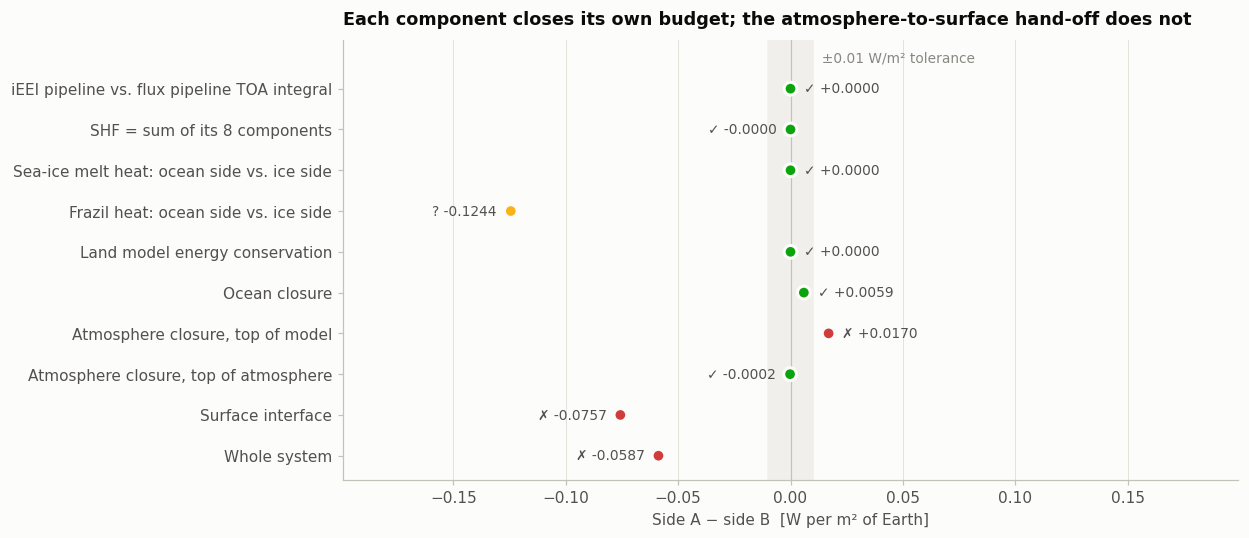

In [19]:
diffs = check_table["A − B [W/m²]"]
symbols = check_table["status"].str[0]
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.axvspan(-TOL, TOL, color=NEUTRAL, zorder=0)
ax.text(TOL, -0.75, f"  ±{TOL} W/m² tolerance", color=MUTED, fontsize=9, va="center")
ax.axvline(0, color=AXIS, lw=0.8)
y = np.arange(len(diffs))
ax.scatter(diffs.values, y, s=70, c=[STATUS_COLOR[s] for s in symbols], zorder=3,
           edgecolors=SURFACE, linewidths=2)
for yi, (d, s) in enumerate(zip(diffs.values, symbols)):
    ax.annotate(f"{s} {d:+.4f}", xy=(d, yi), xytext=(9 if d >= 0 else -9, 0),
                textcoords="offset points", va="center", ha="left" if d >= 0 else "right", color=INK2, fontsize=9)
ax.set_yticks(y, diffs.index)
ax.invert_yaxis()
ax.set_ylim(len(diffs) - 0.4, -1.2)
lim = max(diffs.abs().max() * 1.6, 3 * TOL)
ax.set_xlim(-lim, lim)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Side A − side B  [W per m² of Earth]",
       title="Each component closes its own budget; the atmosphere-to-surface hand-off does not")
plt.show()


### Energy flow, top to bottom

The same budget drawn as a column of atmosphere over the surface; arrow widths are proportional to W/m² of Earth.
The surface hand-off is shown from both sides: what the atmosphere says it delivers (CAM surface net), and what
the surface reservoirs actually store (ocean + sea ice + land, almost all ocean). The surface-side arrow is split into
**drift** — the energy the atmosphere delivers, which originally entered at the top of the model — and **leakage** —
the difference between the two views, energy that appears at the hand-off with no source at the top of the model.


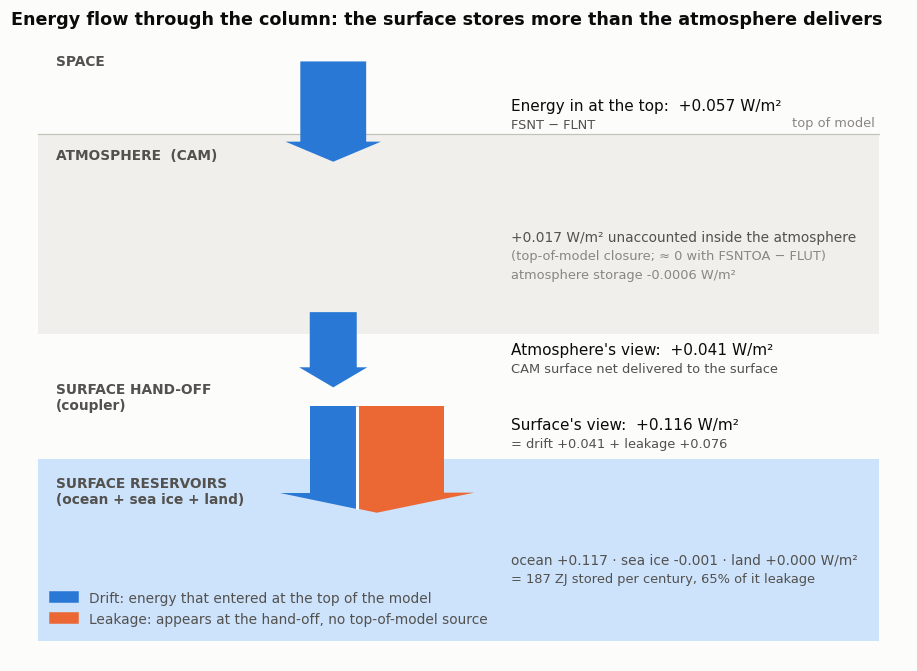

In [20]:

# ENERGY_FLOW_SCHEMATIC
from matplotlib.patches import FancyArrow, Patch, Rectangle

toa = r["toa_model"]                       # FSNT - FLNT
atm_view = r["sfc"]                        # CAM surface net: the atmosphere's view of the hand-off
sfc_view = r["ocn"] + r["ice"] + r["land"]  # what the surface reservoirs store: the surface's view
drift, leak = atm_view, sfc_view - atm_view
atm_residual = toa - atm_view - r["atm"]

SCALE = 1.5 / max(toa, sfc_view)  # diagram width units per W/m^2
GAP = 0.06                        # surface gap between the two side-by-side arrows

fig, ax = plt.subplots(figsize=(10.5, 7.4))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

# Context fills (not data): atmosphere and surface reservoirs.
ax.add_patch(Rectangle((0.3, 5.2), 9.4, 3.2, facecolor=NEUTRAL, edgecolor="none", zorder=0))
ax.add_patch(Rectangle((0.3, 0.3), 9.4, 2.9, facecolor="#cde2fb", edgecolor="none", zorder=0))
ax.plot([0.3, 9.7], [8.4, 8.4], color=AXIS, lw=0.8)
ax.text(9.65, 8.47, "top of model", ha="right", va="bottom", color=MUTED, fontsize=8.5)
for y, label in [(9.55, "SPACE"), (8.05, "ATMOSPHERE  (CAM)"), (4.2, "SURFACE HAND-OFF\n(coupler)"),
                 (2.7, "SURFACE RESERVOIRS\n(ocean + sea ice + land)")]:
    ax.text(0.5, y, label, color=INK2, fontsize=9, fontweight="bold", va="center")


def flow_arrow(x, y_from, y_to, value, color):
    w = value * SCALE
    ax.add_patch(FancyArrow(x, y_from, 0, y_to - y_from, width=w, head_width=w * 1.45, head_length=0.32,
                            length_includes_head=True, color=color, linewidth=0, zorder=3))
    return w


X = 3.6
w_toa = flow_arrow(X, 9.55, 7.95, toa, BLUE)
w_atm = flow_arrow(X, 5.55, 4.35, atm_view, BLUE)


def split_arrow(x_left, y_from, y_to, parts, head_length=0.32, head_over=0.45):
    """One downward arrow whose shaft and head are divided into colored parts, side by side,
    separated by a surface-colored gap -- the parts add up to the arrow's total."""
    from matplotlib.patches import Polygon
    widths = [v * SCALE for v, _ in parts]
    total = sum(widths)
    x_right, xc = x_left + total, x_left + total / 2
    y_head = y_to + head_length
    xl, xr = x_left - head_over * total / 2, x_right + head_over * total / 2
    edges, x = [x_left], x_left
    for w in widths:
        x += w
        edges.append(x)
    for (_, color), a, b in zip(parts, edges[:-1], edges[1:]):
        ax.add_patch(Rectangle((a, y_head), b - a, y_from - y_head, facecolor=color, edgecolor="none", zorder=3))
        # the slice of the head triangle between x = a' and x = b' (outer parts extend to the head's corners)
        a2 = xl if a == x_left else a
        b2 = xr if b == x_right else b
        def y_on_head(xq):
            return y_head + (y_to - y_head) * ((xq - xl) / (xc - xl) if xq <= xc else (xr - xq) / (xr - xc))
        poly = [(a2, y_head), (b2, y_head), (b2, y_on_head(b2))]
        if a2 < xc < b2:
            poly.append((xc, y_to))
        poly.append((a2, y_on_head(a2)))
        ax.add_patch(Polygon(poly, closed=True, facecolor=color, edgecolor="none", zorder=3))
    for e in edges[1:-1]:  # 2px surface gap between the parts
        y_edge = y_head + (y_to - y_head) * ((e - xl) / (xc - xl) if e <= xc else (xr - e) / (xr - xc))
        ax.plot([e, e], [y_from, y_edge], color=SURFACE, lw=2, zorder=4, solid_capstyle="butt")
    return x_right


x_right = split_arrow(X - drift * SCALE / 2, 4.05, 2.35, [(drift, BLUE), (leak, ORANGE)])

LX = max(x_right + 0.75, X + w_toa / 2 + 1.0)  # text column, right of the widest arrow
ax.text(LX, 8.85, f"Energy in at the top:  {toa:+.3f} W/m²", color=INK, fontsize=10, va="center")
ax.text(LX, 8.55, "FSNT − FLNT", color=INK2, fontsize=8.5, va="center")
ax.text(LX, 6.75, f"{atm_residual:+.3f} W/m² unaccounted inside the atmosphere", color=INK2, fontsize=9, va="center")
ax.text(LX, 6.45, "(top-of-model closure; ≈ 0 with FSNTOA − FLUT)", color=MUTED, fontsize=8.5, va="center")
ax.text(LX, 6.15, f"atmosphere storage {r['atm']:+.4f} W/m²", color=MUTED, fontsize=8.5, va="center")
ax.text(LX, 4.95, f"Atmosphere's view:  {atm_view:+.3f} W/m²", color=INK, fontsize=10, va="center")
ax.text(LX, 4.65, "CAM surface net delivered to the surface", color=INK2, fontsize=8.5, va="center")
ax.text(LX, 3.75, f"Surface's view:  {sfc_view:+.3f} W/m²", color=INK, fontsize=10, va="center")
ax.text(LX, 3.45, f"= drift {drift:+.3f} + leakage {leak:+.3f}", color=INK2, fontsize=8.5, va="center")
ax.text(LX, 1.6, f"ocean {r['ocn']:+.3f} · sea ice {r['ice']:+.3f} · land {r['land']:+.3f} W/m²",
        color=INK2, fontsize=9, va="center")
ax.text(LX, 1.3, f"= {sfc_view * EARTH * CENTURY_S / ZJ:.0f} ZJ stored per century, "
        f"{100 * leak / sfc_view:.0f}% of it leakage", color=INK2, fontsize=8.5, va="center")

ax.legend(handles=[Patch(color=BLUE, label="Drift: energy that entered at the top of the model"),
                   Patch(color=ORANGE, label="Leakage: appears at the hand-off, no top-of-model source")],
          loc="lower left", bbox_to_anchor=(0.03, 0.035), fontsize=9)
ax.set_title("Energy flow through the column: the surface stores more than the atmosphere delivers", pad=6)
plt.show()


## 4. Scope: how big is the mismatch?

The unexplained energy is the **whole-system** residual from Section 3: everything the reservoirs stored minus
everything that entered at the top of the model. It is compared below with several reference magnitudes from the
same 100 years. Note that this residual is not sampling noise. Energy conservation holds at every time step, and
every reservoir is counted, so year-to-year weather cannot produce a 100-year residual. Interannual variability is
listed only as a familiar scale.

In [21]:
unexplained = stored - r["toa_model"]  # W/m^2 of Earth
unexplained_J = unexplained * EARTH * CENTURY_S
vol = ohc["ocean_volume_m3"]

eei_annual = annual(flx["TOA_NET_MODEL"]) / EARTH
eei_monthly_clim = (flx["TOA_NET_MODEL"] / EARTH).groupby("time.month").mean()
references = {
    "Ocean heat gained over the century (dOHC)": abs(r["ocn"]),
    "TOA imbalance itself (iEEI rate)": abs(r["toa_model"]),
    "Year-to-year std. dev. of annual-mean TOA imbalance": float(eei_annual.std()),
    "Seasonal range of the TOA imbalance": float(eei_monthly_clim.max() - eei_monthly_clim.min()),
    "Sunlight absorbed by the ocean (SHF_QSW)": flux_mean(flx["SHF_QSW"]),
    "Sunlight absorbed by the planet (FSNT)": flux_mean(flx["FSNT"]),
}
scope = pd.DataFrame({"reference [W/m²]": references})
scope["unexplained as % of reference"] = 100 * abs(unexplained) / scope["reference [W/m²]"]
display(scope.style.format({"reference [W/m²]": "{:.4f}", "unexplained as % of reference": "{:.3g}%"}))

dT_full_mK = 1e3 * unexplained_J / (RHO_CP * float(vol.sel(ohc_depth=-1)))
dT_300_mK = 1e3 * unexplained_J / (RHO_CP * float(vol.sel(ohc_depth=300)))
print(f"Unexplained energy: {unexplained:+.4f} W/m^2 of Earth = {unexplained_J / ZJ:+.1f} ZJ per century")
print(f"  = {dT_full_mK:.1f} mK/century if spread over the full ocean depth")
print(f"  = {dT_300_mK:.0f} mK/century if confined to the top 300 m")
print(f"  sustained over the full ~500-year piControl: {5 * unexplained_J / ZJ:+.0f} ZJ")

,reference [W/m²],unexplained as % of reference
Ocean heat gained over the century (dOHC),0.1167,50.3%
Seasonal range of the TOA imbalance,18.1606,0.323%
Sunlight absorbed by the ocean (SHF_QSW),121.2679,0.0484%
Sunlight absorbed by the planet (FSNT),239.8212,0.0245%
TOA imbalance itself (iEEI rate),0.0571,103%
Year-to-year std. dev. of annual-mean TOA imbalance,0.4356,13.5%


Unexplained energy: +0.0587 W/m^2 of Earth = +94.5 ZJ per century
  = 17.4 mK/century if spread over the full ocean depth
  = 226 mK/century if confined to the top 300 m
  sustained over the full ~500-year piControl: +473 ZJ


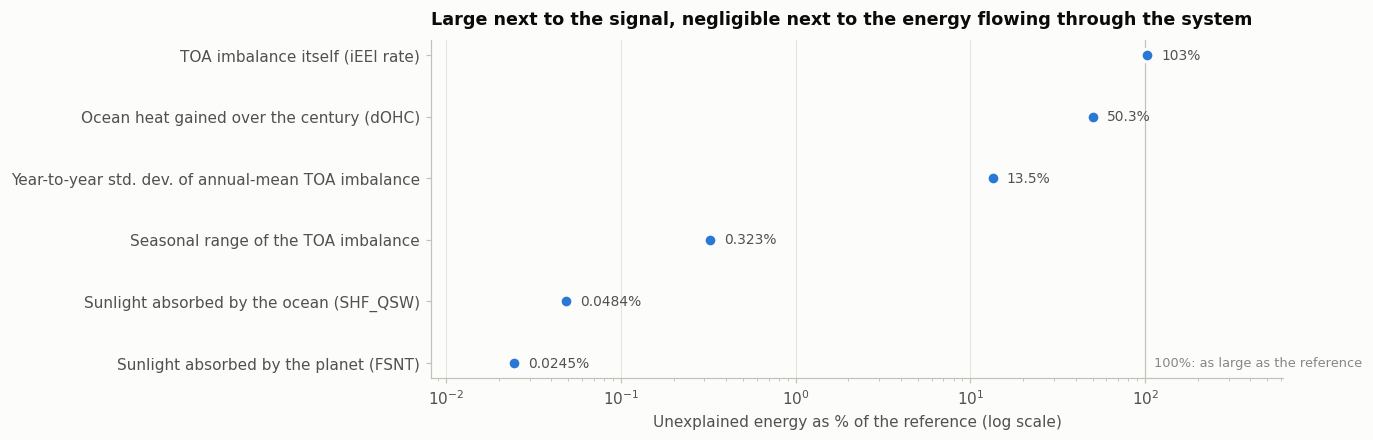

In [22]:
# A dot plot, not bars: on a log axis, bar length carries no meaning.
fig, ax = plt.subplots(figsize=(10, 4))
pct = scope["unexplained as % of reference"].sort_values(ascending=False)
y = np.arange(len(pct))
ax.scatter(pct.values, y, s=70, color=BLUE, zorder=3, edgecolors=SURFACE, linewidths=2)
ax.set_xscale("log")
ax.set_yticks(y, pct.index)
ax.invert_yaxis()
ax.set_xlim(pct.min() / 3, pct.max() * 6)
for yi, v in zip(y, pct.values):
    ax.annotate(f"{v:.3g}%", xy=(v, yi), xytext=(9, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.axvline(100, color=AXIS, lw=0.8)
ax.annotate("100%: as large as the reference", xy=(100, len(pct) - 1), xytext=(6, 0), textcoords="offset points",
            color=MUTED, fontsize=8.5, va="center")
ax.grid(axis="y", visible=False)
ax.set(xlabel="Unexplained energy as % of the reference (log scale)",
       title="Large next to the signal, negligible next to the energy flowing through the system")
plt.show()

## 5. Why surface temperature stays flat while the system gains energy

The question: both OHC and iEEI say the Earth system gains energy, yet global surface temperature in the piControl
is roughly constant. Three numbers answer it: the surface temperature trend, where in the water column the heat
goes, and how much that heat warms each layer given the layer's heat capacity.

In [23]:
ts = annual(flx["TS_GLOBAL_MEAN"])
(ts_slope, _), ts_cov = np.polyfit(ts["year"].values, ts.values, 1, cov=True)
ts_trend, ts_trend_se = ts_slope * 100, np.sqrt(ts_cov[0, 0]) * 100  # K/century (SE assumes independent years)

layers = ["0–300 m", "300–700 m", "700–2000 m", "below 2000 m"]
def layer_split(cumulative):  # cumulative bins (300, 700, 2000, full) -> layers
    c = [cumulative[300], cumulative[700], cumulative[2000], cumulative[-1]]
    return [c[0], c[1] - c[0], c[2] - c[1], c[3] - c[2]]

rate_bins = {int(b): storage_rate(d_ohc.sel(ohc_depth=b)) for b in d_ohc["ohc_depth"].values}
vol_bins = {int(b): float(vol.sel(ohc_depth=b)) for b in vol["ohc_depth"].values}
layer_table = pd.DataFrame({"heat uptake [W/m² of Earth]": layer_split(rate_bins), "volume [m³]": layer_split(vol_bins)}, index=layers)
layer_table["heat gained [ZJ/century]"] = layer_table["heat uptake [W/m² of Earth]"] * EARTH * CENTURY_S / ZJ
layer_table["layer-mean warming [mK/century]"] = 1e3 * layer_table["heat gained [ZJ/century]"] * ZJ / (RHO_CP * layer_table["volume [m³]"])
layer_table["share of ocean heat gain"] = layer_table["heat uptake [W/m² of Earth]"] / r["ocn"]
display(layer_table.style.format({"heat uptake [W/m² of Earth]": "{:+.4f}", "volume [m³]": "{:.3e}",
                                  "heat gained [ZJ/century]": "{:+.1f}", "layer-mean warming [mK/century]": "{:+.1f}",
                                  "share of ocean heat gain": "{:.0%}"}))
print(f"Global-mean surface temperature trend: {ts_trend:+.3f} ± {ts_trend_se:.3f} K/century "
      f"(1 s.e.; year-to-year std. dev. {float(ts.std()):.3f} K)")
print(f"Full-depth ocean warming implied by dOHC: {1e3 * r['ocn'] * EARTH * CENTURY_S / (RHO_CP * vol_bins[-1]):.1f} mK/century")

,heat uptake [W/m² of Earth],volume [m³],heat gained [ZJ/century],layer-mean warming [mK/century],share of ocean heat gain
0–300 m,-0.0138,1.018e+17,-22.1,-53.0,-12%
300–700 m,+0.0144,1.250e+17,+23.2,+45.3,12%
700–2000 m,+0.0508,3.806e+17,+81.7,+52.4,44%
below 2000 m,+0.0653,7.176e+17,+105.0,+35.7,56%


Global-mean surface temperature trend: -0.182 ± 0.037 K/century (1 s.e.; year-to-year std. dev. 0.119 K)
Full-depth ocean warming implied by dOHC: 34.6 mK/century


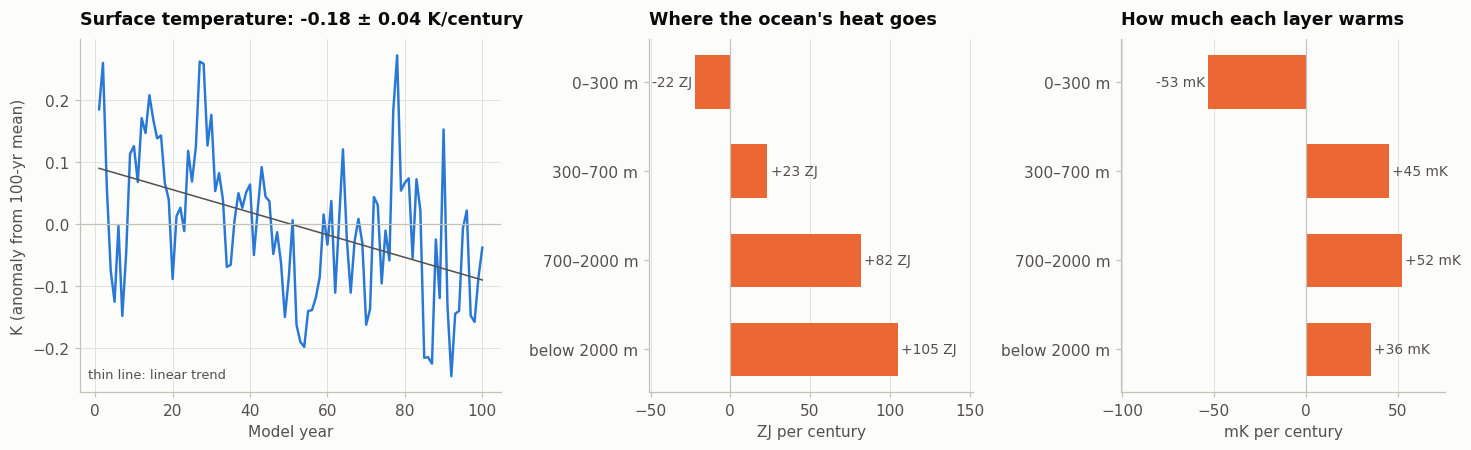

In [24]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13.5, 4.2), gridspec_kw={"width_ratios": [1.3, 1, 1]})

anom = ts - ts.mean()
ax1.plot(anom["year"], anom, color=BLUE, lw=1.6)
fit = np.polyval(np.polyfit(anom["year"].values, anom.values, 1), anom["year"].values)
ax1.plot(anom["year"], fit, color=INK2, lw=1)
ax1.text(0.02, 0.04, "thin line: linear trend", transform=ax1.transAxes, color=INK2, fontsize=8.5)
ax1.axhline(0, color=AXIS, lw=0.8)
ax1.set(xlabel="Model year", ylabel="K (anomaly from 100-yr mean)",
        title=f"Surface temperature: {ts_trend:+.2f} ± {ts_trend_se:.2f} K/century")

heat = layer_table["heat gained [ZJ/century]"]
bars = ax2.barh(layers, heat.values, color=ORANGE, height=0.6)
ax2.invert_yaxis()
ax2.axvline(0, color=AXIS, lw=0.8)
ax2.set_xlim(min(0, heat.min()) * 2.3, heat.max() * 1.45)  # room for the negative bar's label
label_bars(ax2, bars, heat.values, lambda v: f"{v:+.0f} ZJ")
ax2.grid(axis="y", visible=False)
ax2.set(xlabel="ZJ per century", title="Where the ocean's heat goes")

warm = layer_table["layer-mean warming [mK/century]"]
bars = ax3.barh(layers, warm.values, color=ORANGE, height=0.6)
ax3.invert_yaxis()
ax3.axvline(0, color=AXIS, lw=0.8)
ax3.set_xlim(min(0, warm.min()) * 1.9, warm.max() * 1.45)
label_bars(ax3, bars, warm.values, lambda v: f"{v:+.0f} mK")
ax3.grid(axis="y", visible=False)
ax3.set(xlabel="mK per century", title="How much each layer warms")
fig.tight_layout()
plt.show()

**Why the surface stays flat.**

1. **The heat goes deep, not to the surface.** Over the century the top 300 m *loses* heat (≈ −22 ZJ, cooling by
   ≈ 0.05 K). The layers below 700 m gain ≈ 190 ZJ, so all of the ocean's net gain sits below 300 m. Global surface
   temperature follows the upper ocean, and it drifts slightly *down* (−0.18 ± 0.04 K/century), not up.
2. **The deep ocean's heat capacity is enormous.** The ocean holds 1.3 × 10¹⁸ m³ of water at
   4.1 × 10⁶ J m⁻³ K⁻¹, about 5.4 × 10²⁴ J per kelvin. So the ≈ 170 ZJ gained in the century warms the ocean by
   only ≈ 0.035 K on average. That is invisible at the surface, where the year-to-year noise in global-mean surface
   temperature alone is 0.12 K.
3. **This is a deep ocean still spinning up.** The deep water is slightly colder than it would be in equilibrium
   with the fixed pre-industrial surface climate. It takes up heat slowly, through mixing and overturning, over
   centuries to millennia. The surface climate equilibrates in years to decades and is set by the fast surface
   energy balance, so it barely notices how much heat moves downward. From space, a steady positive TOA imbalance
   with a flat surface temperature looks exactly like this: the TOA imbalance is the rate at which the deep ocean
   is still absorbing heat.
4. **About half of the ocean's gain never passed through the top of the atmosphere.** Of the ocean's
   0.117 W/m², 0.059 W/m² has no TOA source (Section 3). It appears at the atmosphere-to-surface hand-off, where
   it enters the surface reservoirs (in practice the ocean) without having been part of the energy balance the
   atmosphere sees, so it does not need to warm the surface either. It just accumulates in the ocean interior
   along with the real deep-ocean uptake.

## 6. Summary

In [25]:
print("VERIFIED (sides agree within ±%.2f W/m^2 of Earth):" % TOL)
for name, row in check_table[check_table["status"].str.startswith("✓")].iterrows():
    print(f"  ✓ {name}: {row['side A']} vs {row['side B']}  (A − B = {row['A − B [W/m²]']:+.4f})")
print("\nCALLED INTO QUESTION:")
for name, row in check_table[check_table["status"].str.startswith("✗")].iterrows():
    print(f"  ✗ {name}: {row['side A']} vs {row['side B']}  (A − B = {row['A − B [W/m²]']:+.4f})")
print("\nINCONCLUSIVE (approximate comparison outside tolerance):")
for name, row in check_table[check_table["status"].str.startswith("?")].iterrows():
    print(f"  ? {name}: {row['side A']} vs {row['side B']}  (A − B = {row['A − B [W/m²]']:+.4f}; {row['notes']})")

VERIFIED (sides agree within ±0.01 W/m^2 of Earth):
  ✓ iEEI pipeline vs. flux pipeline TOA integral: iEEI_total_joules / 100 yr vs flux-pipeline FSNT − FLNT  (A − B = +0.0000)
  ✓ SHF = sum of its 8 components: SHF vs sum of components  (A − B = -0.0000)
  ✓ Sea-ice melt heat: ocean side vs. ice side: POP MELTH_F vs CICE fhocn_ai  (A − B = +0.0000)
  ✓ Land model energy conservation: CLM ERRSEB + ERRSOI + ERRSOL vs zero  (A − B = +0.0000)
  ✓ Ocean closure: dOHC/dt (from TEMP) vs SHF + QFLUX + TFW_T + RESID_T  (A − B = +0.0059)
  ✓ Atmosphere closure, top of atmosphere: TOA: FSNTOA − FLUT vs surface net + atm. storage  (A − B = -0.0002)

CALLED INTO QUESTION:
  ✗ Atmosphere closure, top of model: TOA: FSNT − FLNT vs surface net + atm. storage  (A − B = +0.0170)
  ✗ Surface interface: CAM surface net vs ocean + sea-ice + land storage  (A − B = -0.0757)
  ✗ Whole system: TOA: FSNT − FLNT (iEEI) vs ocean + sea-ice + land + atm. storage  (A − B = -0.0587)

INCONCLUSIVE (approximate compar

**Verified: the calculations and each component's own books.**
- The iEEI integral is computed correctly. Two independent pipelines agree exactly.
- POP's `SHF` equals the sum of its eight coupler components when CESM's latent heats are used, so the flux
  decomposition and its constants are right.
- **The OHC calculation is correct.** The heat-content change computed from `TEMP` matches the heat POP's own
  fluxes deliver (SHF + QFLUX) to within 0.006 W/m² (5%). The ≈ 2× gap is not an OHC bug.
- Ice-to-ocean melt heat agrees on both sides of the coupler. CLM reports no energy-conservation error.
  Sea-ice, land and atmosphere storage are each under 0.001 W/m².
- The atmosphere closes its own budget, to within 0.0002 W/m², when TOA is defined as **FSNTOA − FLUT**.

**Called into question: the energy hand-offs.**
- **The atmosphere-to-surface hand-off (−0.076 W/m²).** The ocean, sea ice and land together store
  0.116 W/m², but CAM delivers only 0.041 W/m² to the surface. This is where the ocean's extra energy enters.
  Two ocean terms point at the likely cause. Frazil heat (`QFLUX`, 0.047 W/m²) is the term closest in size to
  the gap, and `SHF` on its own (0.063 W/m²) is much closer to CAM's surface net. That makes the bookkeeping of
  ice formation between POP and CICE the leading suspect.
- **iEEI's TOA definition (+0.017 W/m²).** FSNT − FLNT (top of model) does not close against the surface budget,
  while FSNTOA − FLUT does. Switching `config.ASR_VAR`/`OLR_VAR` to FSNTOA/FLUT would make iEEI consistent with
  the rest of the atmosphere's budget, but it would *widen* the OHC/iEEI ratio from ≈ 2.0× to ≈ 2.9×.
- **The whole system (−0.059 W/m²).** Net effect of the two problems above: the climate system stores about
  twice the energy that enters at the top of the model.

**Inconclusive.**
- **The frazil comparison.** Converting CICE's `frazil` diagnostic with ρ_ice·L_f gives ≈ 3.6× POP's
  `QFLUX`. But CICE's sea-ice heat content is flat over the century, so CICE is not actually creating that much
  extra ice; the two monthly diagnostics simply aren't defined the same way. Testing the frazil hypothesis needs
  the coupler-level exchange fields: the freeze/melt potential POP sends, and the frazil heat CICE receives.

**Scope.**
- The unexplained 0.059 W/m² is about half of the century's ocean heat gain, and as large as the TOA imbalance
  itself, so it dominates any OHC-vs-iEEI comparison in this run.
- It is also only 0.02% of the sunlight the planet absorbs, and ≈ 14% of the year-to-year scatter in the TOA
  imbalance: the size of energy-conservation error a coupled model can carry with no visible effect on its
  climate.
- It accumulates, though: ≈ 95 ZJ per century, and ≈ 470 ZJ over the full ≈ 500-year control run. That is
  equivalent to ≈ 0.017 K per century of full-depth ocean warming that has no TOA source.

**Next steps.**
1. Compare POP's `QFLUX` with the frazil and melt-potential heat CICE actually receives through the coupler
   (coupler history, or CICE `frzmlt`), to test the frazil-bookkeeping hypothesis.
2. Check CESM2(WACCM6) documentation and known issues for a coupled surface energy leak of this size.
3. Decide whether iEEI should use FSNTOA − FLUT, and if so rerun `run_ieei_piControl.py`.